Total transaksi unik : 9465
Total variasi item   : 94
Contoh 5 transaksi pertama:
T1: ['Bread']
T2: ['Scandinavian']
T3: ['Hot chocolate', 'Jam', 'Cookies']
T4: ['Muffin']
T5: ['Coffee', 'Pastry', 'Bread']

Ukuran matriks one-hot: (9465, 94)

Jumlah frequent itemset (min_support=0.015): 46
 support         itemsets
0.478394         (Coffee)
0.327205          (Bread)
0.142631            (Tea)
0.103856           (Cake)
0.090016  (Bread, Coffee)
0.086107         (Pastry)
0.071844       (Sandwich)
0.061807      (Medialuna)
0.058320  (Hot chocolate)
0.054728   (Cake, Coffee)
0.054411        (Cookies)
0.049868    (Tea, Coffee)
0.047544 (Pastry, Coffee)
0.040042        (Brownie)
0.039197     (Farm House)

Jumlah aturan asosiasi (min_confidence=0.3): 15
    antecedents consequents  support  confidence  lift
        (Toast)    (Coffee)    0.024       0.704 1.472
    (Medialuna)    (Coffee)    0.035       0.569 1.190
       (Pastry)    (Coffee)    0.048       0.552 1.154
    (Alfajores)    (Coff

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


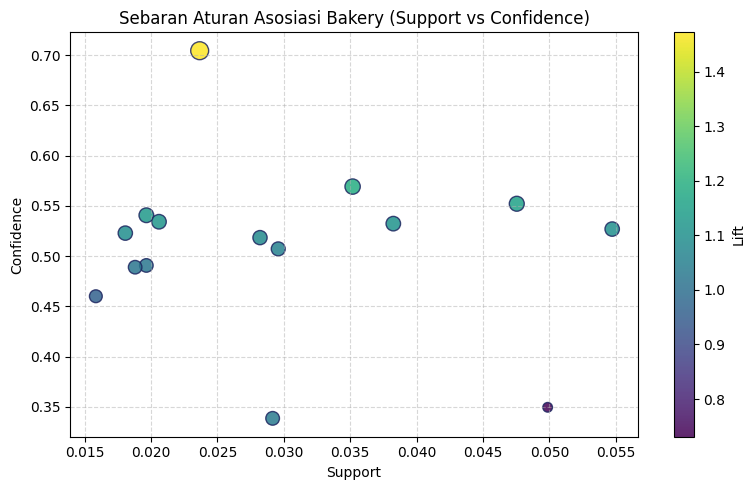

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

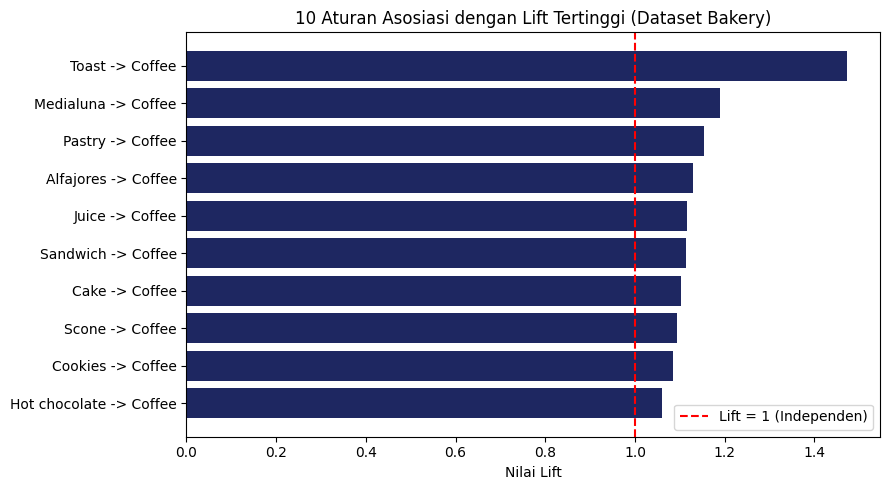

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# ==========================================
# TAHAP 1: PEMUATAN & PEMBERSIHAN DATA
# ==========================================
df_raw = pd.read_csv('Bakery.csv')

# Menghapus baris kosong atau nilai 'NONE' jika ada, serta duplikat item dalam 1 transaksi
df_clean = df_raw.dropna(subset=['TransactionNo', 'Items'])
df_clean = df_clean[df_clean['Items'].str.upper() != 'NONE']
df_clean = df_clean.drop_duplicates(subset=['TransactionNo', 'Items'])

# Mengelompokkan item berdasarkan TransactionNo menjadi list of lists
transactions = df_clean.groupby('TransactionNo')['Items'].apply(list).tolist()

print(f"Total transaksi unik : {len(transactions)}")
print(f"Total variasi item   : {df_clean['Items'].nunique()}")
print("Contoh 5 transaksi pertama:")
for i, t in enumerate(transactions[:5], 1):
    print(f"T{i}: {t}")

# ==========================================
# TAHAP 2: ENCODING ONE-HOT
# ==========================================
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_onehot = pd.DataFrame(te_ary, columns=te.columns_)

print("\nUkuran matriks one-hot:", df_onehot.shape)

# ==========================================
# TAHAP 3: PENCARIAN FREQUENT ITEMSET (APRIORI)
# ==========================================
MIN_SUP = 0.015  # 1.5% dari total transaksi (~142 transaksi)
freq_items = apriori(df_onehot, min_support=MIN_SUP, use_colnames=True)
freq_items = freq_items.sort_values('support', ascending=False).reset_index(drop=True)

print(f"\nJumlah frequent itemset (min_support={MIN_SUP}): {len(freq_items)}")
print(freq_items.head(15).to_string(index=False))

# ==========================================
# TAHAP 4: PEMBENTUKAN ATURAN ASOSIASI
# ==========================================
MIN_CONF = 0.30  # Minimal confidence 30%
rules = association_rules(freq_items, metric='confidence', min_threshold=MIN_CONF)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)

print(f"\nJumlah aturan asosiasi (min_confidence={MIN_CONF}): {len(rules)}")
cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
print(rules[cols].round(3).to_string(index=False))

# ==========================================
# TAHAP 5: VISUALISASI HASIL
# ==========================================
# 5a. Scatter Plot Support vs Confidence (ukuran & warna = Lift)
plt.figure(figsize=(8, 5))
sizes = (rules['lift'] - rules['lift'].min() + 0.3) * 160
sc = plt.scatter(rules['support'], rules['confidence'], s=sizes,
                 c=rules['lift'], cmap='viridis', alpha=0.85, edgecolor='#1E2761')
plt.colorbar(sc, label='Lift')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.title('Sebaran Aturan Asosiasi Bakery (Support vs Confidence)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 5b. Bar Chart Aturan dengan Lift Tertinggi (Top 10)
top_rules = rules.head(10).copy()
top_rules['rule_label'] = (
    top_rules['antecedents'].apply(lambda x: ', '.join(list(x))) +
    ' -> ' +
    top_rules['consequents'].apply(lambda x: ', '.join(list(x)))
)

plt.figure(figsize=(9, 5))
plt.barh(top_rules['rule_label'][::-1], top_rules['lift'][::-1], color='#1E2761')
plt.axvline(x=1.0, color='red', linestyle='--', label='Lift = 1 (Independen)')
plt.xlabel('Nilai Lift')
plt.title('10 Aturan Asosiasi dengan Lift Tertinggi (Dataset Bakery)')
plt.legend()
plt.tight_layout()
plt.show()